# RehaPiano EXACT_FORCE – štatistická analýza

Obsah:
1. Porovnanie zdravých a pacientov podľa veku (histogram po 10 rokoch)
2. Pacienti, ktorí slabo používajú jednu ruku
3. Kvalita dát po prstoch
4. Tremor jednotlivých prstov – ktoré prsty sa trasú viac
5. Rozdiely medzi prstami u jedného človeka
6. Porovnanie skupín po prstoch
7. Príklad spektra prstov

Vstupy: `outputs/*.csv` (`scripts/build_dataset.py`) a `outputs/stats/*.csv` (`scripts/run_analysis.py`).

**Upozornenie:** zdraví a pacienti robili cvičenie s rôznym `step_id` a pacienti sú výrazne starší –
rozdiely medzi skupinami môžu čiastočne vyplývať z nastavenia hry a z veku.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap

# Make the project package importable whether the notebook runs from notebooks/ or the root.
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from rehapiano.config import ALPHA, AGE_MATCHED_MIN_AGE, TREMOR_BAND
from rehapiano.features.spectral import band_mask, compute_spectrogram
from rehapiano.io.metadata import resolve_project_path
from rehapiano.preprocessing.pipeline import load_measurement_data

OUT = ROOT / "outputs"
STATS = OUT / "stats"
attempts = pd.read_csv(OUT / "features_by_attempt_finger.csv")
person_fingers = pd.read_csv(OUT / "features_by_person_finger.csv")
tables = {path.stem: pd.read_csv(path) for path in sorted(STATS.glob("*.csv"))}

In [2]:
# Shared style: thin marks, recessive grid, fixed group colours (validated pair).
GROUP_COLORS = {"control": "#2a78d6", "patient": "#eb6834"}
FINGER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # categorical slots 1-5
TEXT, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 10,
})

# Slovak labels for every category used in the plots.
SK_GROUP = {"control": "Zdraví", "patient": "Pacienti"}
SK_HAND = {"left": "Ľavá ruka", "right": "Pravá ruka"}
FINGERS = ["little", "ring", "middle", "index", "thumb"]
SK_FINGER = {"little": "malíček", "ring": "prstenník", "middle": "prostredník", "index": "ukazovák", "thumb": "palec"}
SK_FEATURE = {
    "tremor_mean_amplitude": "Priemerná amplitúda tremoru",
    "tremor_mean_frequency_hz": "Priemerná frekvencia tremoru [Hz]",
    "tremor_peak_frequency_hz": "Frekvencia vrcholu tremoru [Hz]",
    "tremor_peak_amplitude": "Amplitúda vrcholu tremoru",
    "mean_force": "Priemerná sila",
    "tremor_to_movement_ratio": "Pomer tremor / pohyb",
    "tremor_peak_prominence": "Výraznosť vrcholu tremoru",
}
GROUPS = ["control", "patient"]
HANDS = ["left", "right"]

## 1. Vek: zdraví vs. pacienti

Každá osoba je započítaná raz. Jeden stĺpec = 10 rokov.

In [3]:
display(tables["demographics_by_group"].set_index("group").rename(columns=SK_GROUP).round(1).T
        .rename(columns=SK_GROUP))
display(tables["age_test"].round(4))

group,Zdraví,Pacienti
n_people,90.0,48.0
n_measurements,180.0,83.0
age_mean,35.6,62.7
age_sd,19.6,17.2
age_median,24.0,66.5
age_q1,22.0,56.0
age_q3,52.2,74.2
age_min,18.0,21.0
age_max,85.0,89.0
n_female,36.0,20.0


,variable,n_a,n_b,median_a,median_b,u,p,effect_r
0,age,90,48,24.0,66.5,3585.0,0.0,0.6597


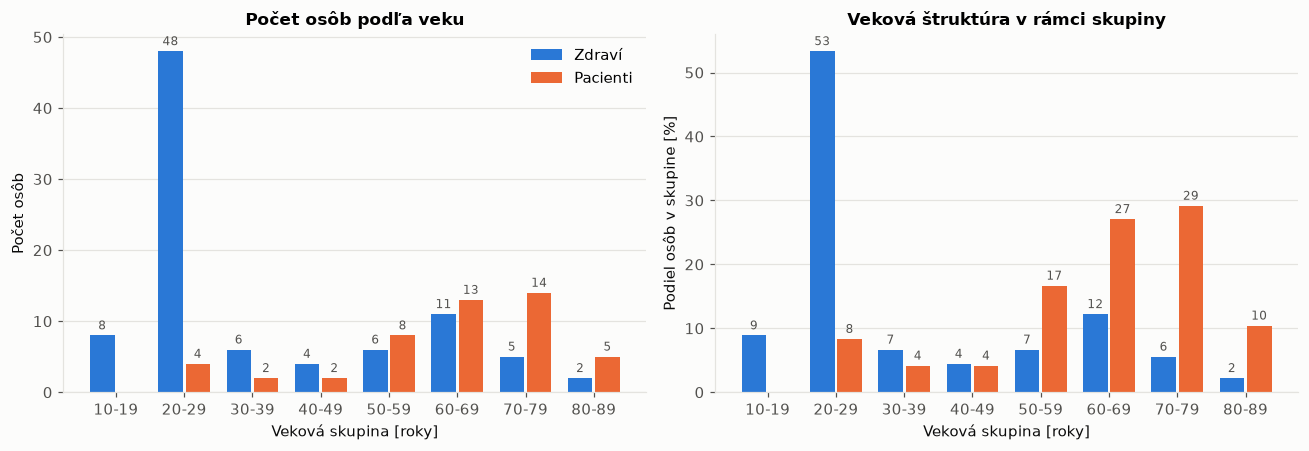

In [4]:
histogram = tables["age_histogram"]
x = np.arange(len(histogram))
width = 0.4
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, suffix, ylabel in ((axes[0], "", "Počet osôb"), (axes[1], "_percent", "Podiel osôb v skupine [%]")):
    for offset, group in zip((-width / 2, width / 2), GROUPS):
        values = histogram[group + suffix]
        bars = ax.bar(x + offset, values, width - 0.04, color=GROUP_COLORS[group], label=SK_GROUP[group])
        labels = [f"{v:.0f}" if v > 0 else "" for v in values]
        ax.bar_label(bars, labels=labels, padding=2, fontsize=8, color=MUTED)
    ax.set_xticks(x, histogram["age_group"])
    ax.set_xlabel("Veková skupina [roky]")
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
axes[0].set_title("Počet osôb podľa veku")
axes[1].set_title("Veková štruktúra v rámci skupiny")
axes[0].legend()
fig.tight_layout()
plt.show()

In [5]:
gender = tables["gender_by_age_group"].pivot_table(index="age_group", columns=["group", "gender"],
                                                   values="n_people", fill_value=0)
gender.columns = [f"{SK_GROUP[g]} – {'ženy' if s == 'female' else 'muži'}" for g, s in gender.columns]
display(gender.astype(int))

,Zdraví – ženy,Zdraví – muži,Pacienti – ženy,Pacienti – muži
age_group,,,,
10-19,1,7,0,0
20-29,11,37,2,2
30-39,2,4,0,2
40-49,2,2,0,2
50-59,4,2,3,5
60-69,10,1,1,12
70-79,4,1,10,4
80-89,2,0,4,1


## 2. Slabo používaná ruka

Pomer slabšej ruky k silnejšej (1 = obe ruky rovnako):
* **pomer sily** – priemerná sila prstov; nízky, keď ruka skoro netlačí,
* **pomer kolísania** – priemerná amplitúda kolísania sily (4–15 Hz); nízky, keď ruka síce leží na snímačoch, ale aktívne nepracuje.

Pevný prah neexistuje, preto sú počty uvedené pre viac prahov.

In [6]:
counts = tables["weak_hand_counts"].copy()
counts["metric"] = counts["metric"].map({"force_ratio": "pomer sily", "fluctuation_ratio": "pomer kolísania"})
counts["group"] = counts["group"].map(SK_GROUP)
display(counts.rename(columns={"metric": "ukazovateľ", "threshold": "prah", "group": "skupina",
                               "n_people": "osoby", "n_below": "pod prahom", "percent_below": "% pod prahom",
                               "patient_ids": "ID"}).round(1))

,ukazovateľ,prah,skupina,osoby,pod prahom,% pod prahom,ID
0,pomer sily,0.1,Zdraví,90,0,0.0,NaN
1,pomer sily,0.1,Pacienti,48,0,0.0,NaN
2,pomer sily,0.2,Zdraví,90,1,1.1,20250228004
3,pomer sily,0.2,Pacienti,48,1,2.1,0IKB-27Y1
4,pomer sily,0.5,Zdraví,90,2,2.2,"20250228004, 1302202521"
5,pomer sily,0.5,Pacienti,48,6,12.5,"0IKB-27Y1, 3OUS-NI9J, EJIT-XSEZ, ILHC-BZCP, W6..."
6,pomer kolísania,0.1,Zdraví,90,0,0.0,NaN
7,pomer kolísania,0.1,Pacienti,48,0,0.0,NaN
8,pomer kolísania,0.2,Zdraví,90,0,0.0,NaN
9,pomer kolísania,0.2,Pacienti,48,2,4.2,"0IKB-27Y1, 2REJ-DLCV"


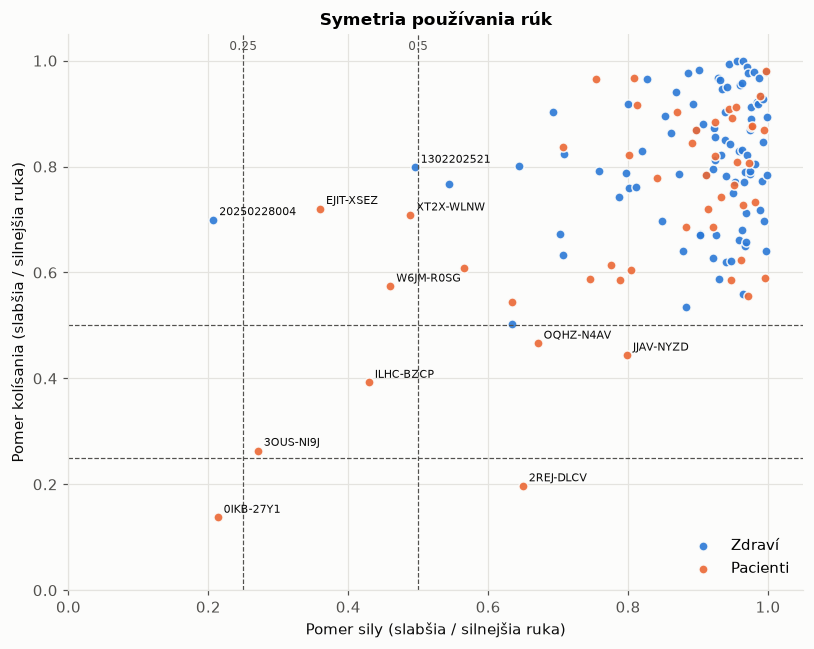

In [7]:
activity = tables["hand_activity"]
fig, ax = plt.subplots(figsize=(7.5, 6))
for group in GROUPS:
    frame = activity.loc[activity["group"] == group]
    ax.scatter(frame["force_ratio"], frame["fluctuation_ratio"], s=36, color=GROUP_COLORS[group],
               edgecolor="#fcfcfb", linewidth=1, label=SK_GROUP[group], alpha=0.9)
for threshold in (0.25, 0.5):
    ax.axvline(threshold, color=MUTED, linewidth=0.8, linestyle="--")
    ax.axhline(threshold, color=MUTED, linewidth=0.8, linestyle="--")
    ax.text(threshold, 1.02, f"{threshold}", color=MUTED, fontsize=8, ha="center")
# Label only the people below 0.5 on either ratio.
weak = activity.loc[(activity["force_ratio"] < 0.5) | (activity["fluctuation_ratio"] < 0.5)]
for row in weak.itertuples():
    ax.annotate(row.patient_id, (row.force_ratio, row.fluctuation_ratio), xytext=(4, 3),
                textcoords="offset points", fontsize=7.5, color=TEXT)
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Pomer sily (slabšia / silnejšia ruka)")
ax.set_ylabel("Pomer kolísania (slabšia / silnejšia ruka)")
ax.set_title("Symetria používania rúk")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## 3. Kvalita dát po prstoch

Všetky signály prešli technickou kontrolou. Prst je **neaktívny**, keď jeho priemerná sila
je v rozsahu nezaťaženého snímača (< 0,002); jeho tremorové ukazovatele sa ďalej nepoužívajú.

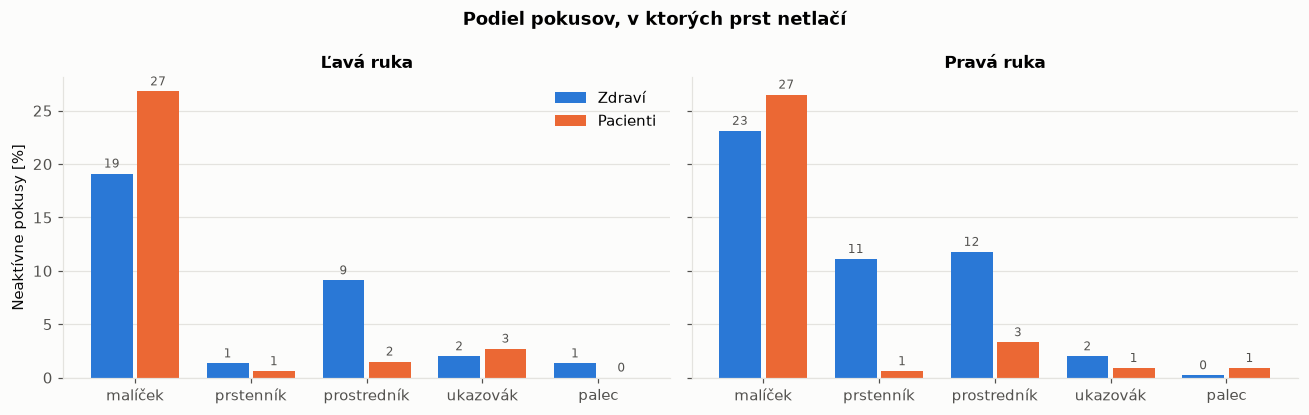

In [8]:
valid = attempts.loc[attempts["status"] == "valid"]
inactive = (valid.groupby(["group", "hand", "finger_name"])["finger_inactive"].mean() * 100).rename("percent")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
x = np.arange(len(FINGERS))
for ax, hand in zip(axes, HANDS):
    for offset, group in zip((-0.2, 0.2), GROUPS):
        values = inactive.loc[group, hand].reindex(FINGERS)
        bars = ax.bar(x + offset, values, 0.36, color=GROUP_COLORS[group], label=SK_GROUP[group])
        ax.bar_label(bars, fmt="%.0f", padding=2, fontsize=8, color=MUTED)
    ax.set_xticks(x, [SK_FINGER[f] for f in FINGERS])
    ax.set_title(SK_HAND[hand])
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Neaktívne pokusy [%]")
axes[0].legend()
fig.suptitle("Podiel pokusov, v ktorých prst netlačí", fontweight="bold")
fig.tight_layout()
plt.show()

## 4. Tremor jednotlivých prstov

Hodnoty na úrovni osoby (priemer meraní). Neaktívne prsty sú vynechané.
Friedmanov test porovnáva päť prstov tej istej osoby; Kendallovo W ukazuje, nakoľko
majú osoby rovnaké poradie prstov (0 = žiadna zhoda, 1 = úplná zhoda).

In [9]:
friedman = tables["finger_friedman"].copy()
friedman["group"] = friedman["group"].map(SK_GROUP)
friedman["hand"] = friedman["hand"].map(SK_HAND)
friedman["feature"] = friedman["feature"].map(SK_FEATURE)
display(friedman.round(4))

,group,hand,feature,n_subjects,chi2,p,kendall_w,median_little,median_ring,median_middle,median_index,median_thumb
0,Zdraví,Ľavá ruka,Pomer tremor / pohyb,65,62.1169,0.0000,0.2389,0.1841,0.1607,0.1511,0.1443,0.1307
1,Zdraví,Ľavá ruka,Priemerná amplitúda tremoru,65,172.4062,0.0000,0.6631,0.0000,0.0000,0.0000,0.0000,0.0000
2,Zdraví,Ľavá ruka,Frekvencia vrcholu tremoru [Hz],65,3.8641,0.4247,0.0149,5.4500,5.5000,5.4000,5.3000,5.2500
3,Zdraví,Ľavá ruka,Výraznosť vrcholu tremoru,65,41.8338,0.0000,0.1609,2.7267,2.4615,2.6816,2.9239,2.9901
4,Zdraví,Pravá ruka,Pomer tremor / pohyb,59,115.2136,0.0000,0.4882,0.2288,0.1754,0.1506,0.1385,0.1342
5,Zdraví,Pravá ruka,Priemerná amplitúda tremoru,59,178.7254,0.0000,0.7573,0.0000,0.0000,0.0000,0.0000,0.0000
6,Zdraví,Pravá ruka,Frekvencia vrcholu tremoru [Hz],59,12.7528,0.0125,0.0540,5.6500,5.2000,5.2000,5.4000,5.4833
7,Zdraví,Pravá ruka,Výraznosť vrcholu tremoru,59,31.0102,0.0000,0.1314,2.4553,2.5954,2.6790,2.8111,2.9180
8,Pacienti,Ľavá ruka,Pomer tremor / pohyb,35,53.6000,0.0000,0.3829,0.1682,0.1206,0.1073,0.0998,0.0925
9,Pacienti,Ľavá ruka,Priemerná amplitúda tremoru,35,108.7314,0.0000,0.7767,0.0000,0.0000,0.0000,0.0000,0.0000


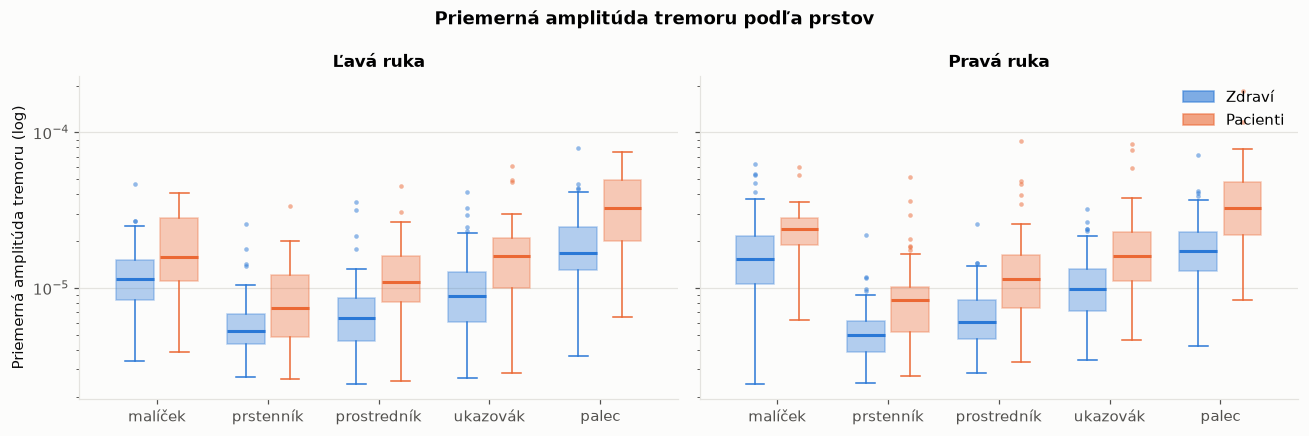

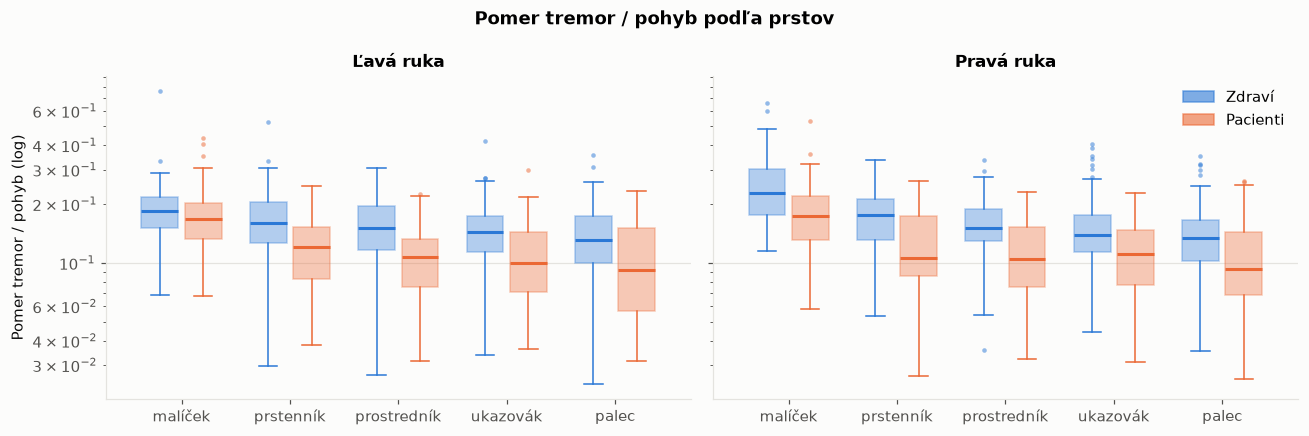

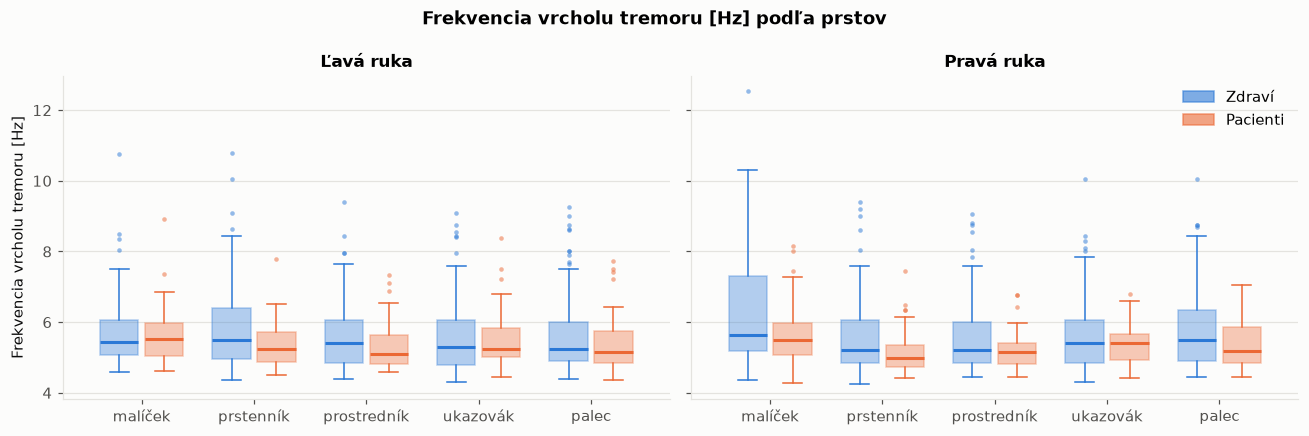

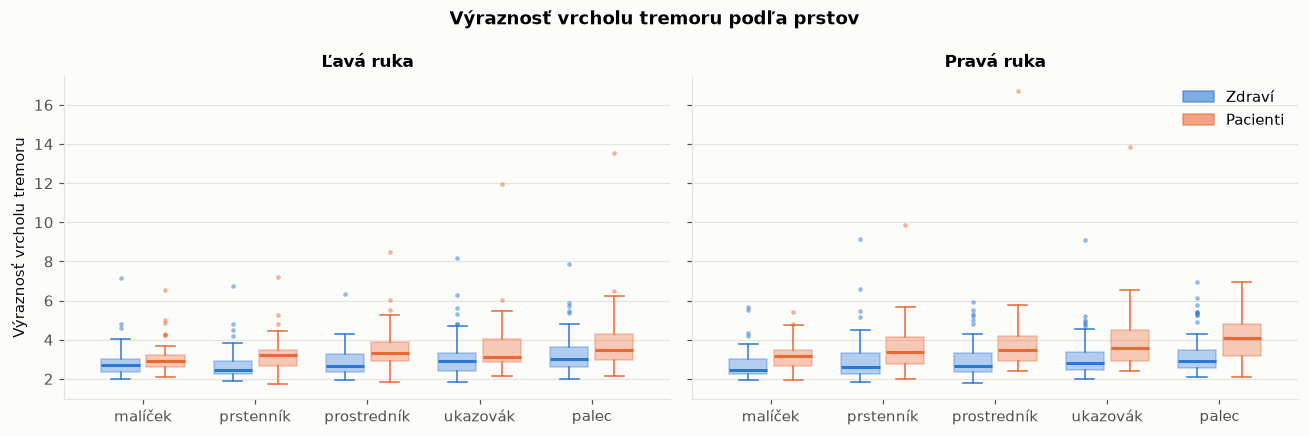

In [10]:
def finger_boxplots(feature, log=False):
    """Boxplots per finger, side by side for the two groups, one panel per hand."""
    data = person_fingers.loc[person_fingers["step_id"].isin(activity["step_id"].unique())]
    data = data.loc[~data["finger_inactive"].astype(bool)]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    x = np.arange(len(FINGERS))
    for ax, hand in zip(axes, HANDS):
        for offset, group in zip((-0.2, 0.2), GROUPS):
            frame = data.loc[(data["hand"] == hand) & (data["group"] == group)]
            values = [frame.loc[frame["finger_name"] == f, feature].dropna() for f in FINGERS]
            ax.boxplot(values, positions=x + offset, widths=0.34, patch_artist=True, showfliers=True,
                       boxprops=dict(facecolor=GROUP_COLORS[group], edgecolor=GROUP_COLORS[group], alpha=0.35),
                       medianprops=dict(color=GROUP_COLORS[group], linewidth=2),
                       whiskerprops=dict(color=GROUP_COLORS[group]), capprops=dict(color=GROUP_COLORS[group]),
                       flierprops=dict(marker="o", markersize=3, markerfacecolor=GROUP_COLORS[group],
                                       markeredgecolor="none", alpha=0.5))
        ax.set_xticks(x, [SK_FINGER[f] for f in FINGERS])
        ax.set_title(SK_HAND[hand])
        ax.grid(axis="x", visible=False)
        if log:
            ax.set_yscale("log")
    axes[0].set_ylabel(SK_FEATURE[feature] + (" (log)" if log else ""))
    handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS[g], alpha=0.6) for g in GROUPS]
    axes[1].legend(handles, [SK_GROUP[g] for g in GROUPS], loc="upper right")
    fig.suptitle(SK_FEATURE[feature] + " podľa prstov", fontweight="bold")
    fig.tight_layout()
    plt.show()

finger_boxplots("tremor_mean_amplitude", log=True)
finger_boxplots("tremor_to_movement_ratio", log=True)
finger_boxplots("tremor_peak_frequency_hz")
finger_boxplots("tremor_peak_prominence")

**Ktorý prst sa trasie najviac?** Podiel osôb, u ktorých má daný prst najvyšší pomer tremor / pohyb.

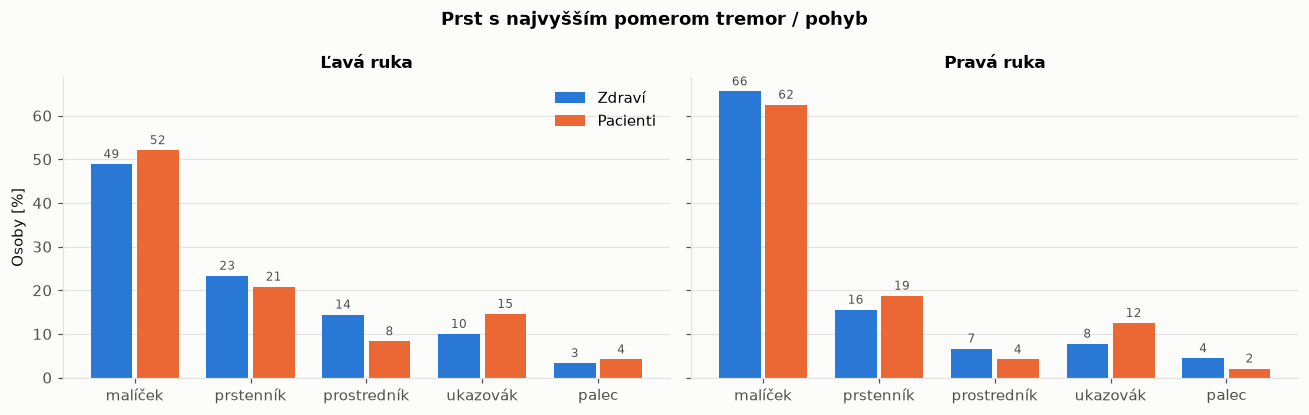

In [11]:
winners = tables["most_tremulous_finger"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
x = np.arange(len(FINGERS))
for ax, hand in zip(axes, HANDS):
    for offset, group in zip((-0.2, 0.2), GROUPS):
        frame = winners.loc[(winners["hand"] == hand) & (winners["group"] == group)].set_index("finger_name")
        values = frame["percent"].reindex(FINGERS).fillna(0)
        bars = ax.bar(x + offset, values, 0.36, color=GROUP_COLORS[group], label=SK_GROUP[group])
        ax.bar_label(bars, fmt="%.0f", padding=2, fontsize=8, color=MUTED)
    ax.set_xticks(x, [SK_FINGER[f] for f in FINGERS])
    ax.set_title(SK_HAND[hand])
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Osoby [%]")
axes[0].legend()
fig.suptitle("Prst s najvyšším pomerom tremor / pohyb", fontweight="bold")
fig.tight_layout()
plt.show()

## 5. Rozdiely medzi prstami u jedného človeka

Každá čiara je jedna osoba: amplitúda tremoru prsta vydelená priemerom jej aktívnych prstov
(1 = priemer osoby). Hrubá čiara je medián skupiny.

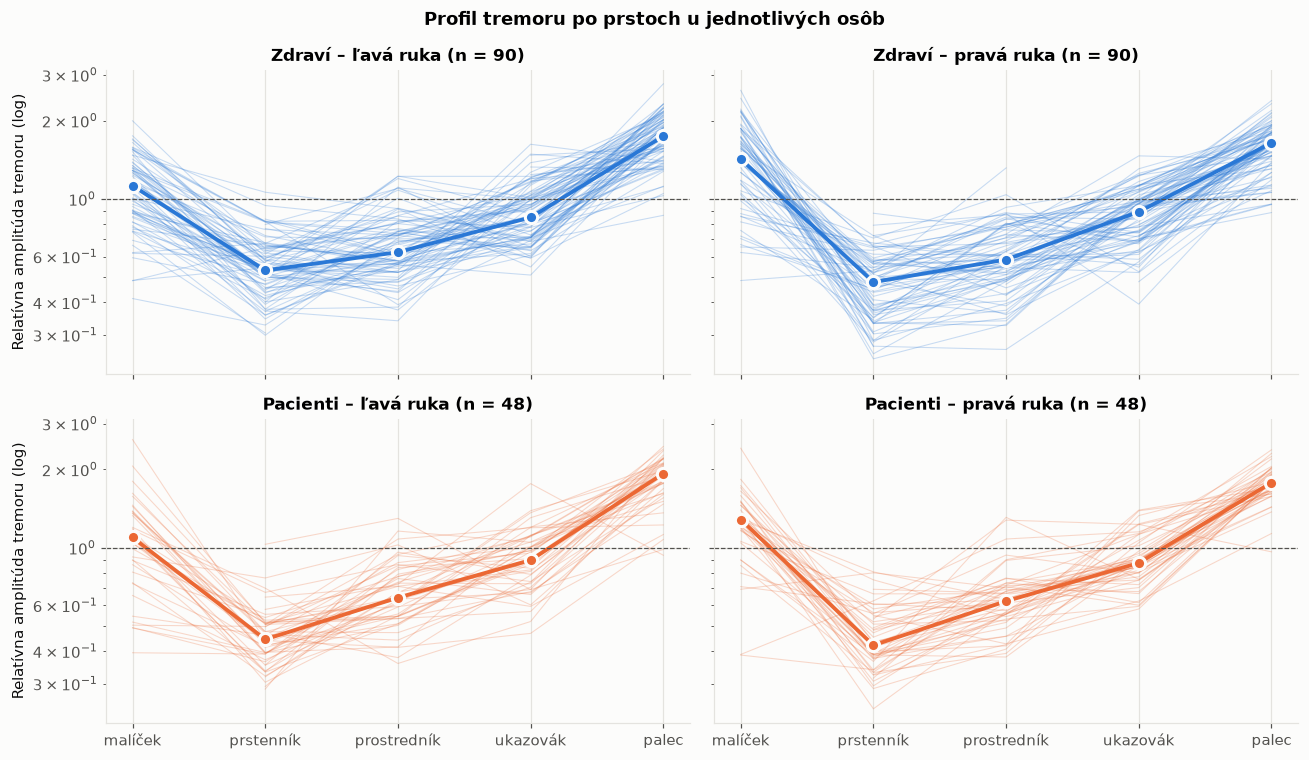

In [12]:
feature = "tremor_mean_amplitude"
data = person_fingers.loc[person_fingers["step_id"].isin(activity["step_id"].unique())].copy()
data.loc[data["finger_inactive"].astype(bool), feature] = np.nan
data["relative"] = data[feature] / data.groupby(["patient_id", "hand"])[feature].transform("mean")
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
x = np.arange(len(FINGERS))
for row, group in enumerate(GROUPS):
    for col, hand in enumerate(HANDS):
        ax = axes[row, col]
        wide = data.loc[(data["group"] == group) & (data["hand"] == hand)].pivot_table(
            index="patient_id", columns="finger_name", values="relative").reindex(columns=FINGERS)
        for values in wide.to_numpy():
            ax.plot(x, values, color=GROUP_COLORS[group], linewidth=0.7, alpha=0.25)
        ax.plot(x, wide.median(), color=GROUP_COLORS[group], linewidth=2.5, marker="o", markersize=8,
                markeredgecolor="#fcfcfb", markeredgewidth=2)
        ax.axhline(1, color=MUTED, linewidth=0.8, linestyle="--")
        ax.set_yscale("log")
        ax.set_title(f"{SK_GROUP[group]} – {SK_HAND[hand].lower()} (n = {len(wide)})")
        ax.set_xticks(x, [SK_FINGER[f] for f in FINGERS])
for ax in axes[:, 0]:
    ax.set_ylabel("Relatívna amplitúda tremoru (log)")
fig.suptitle("Profil tremoru po prstoch u jednotlivých osôb", fontweight="bold")
fig.tight_layout()
plt.show()

**Rozptyl medzi prstami:** variačný koeficient (CV = smerodajná odchýlka / priemer cez aktívne prsty)
na osobu a ruku. Vyšší CV = väčšie rozdiely medzi prstmi tej istej osoby.

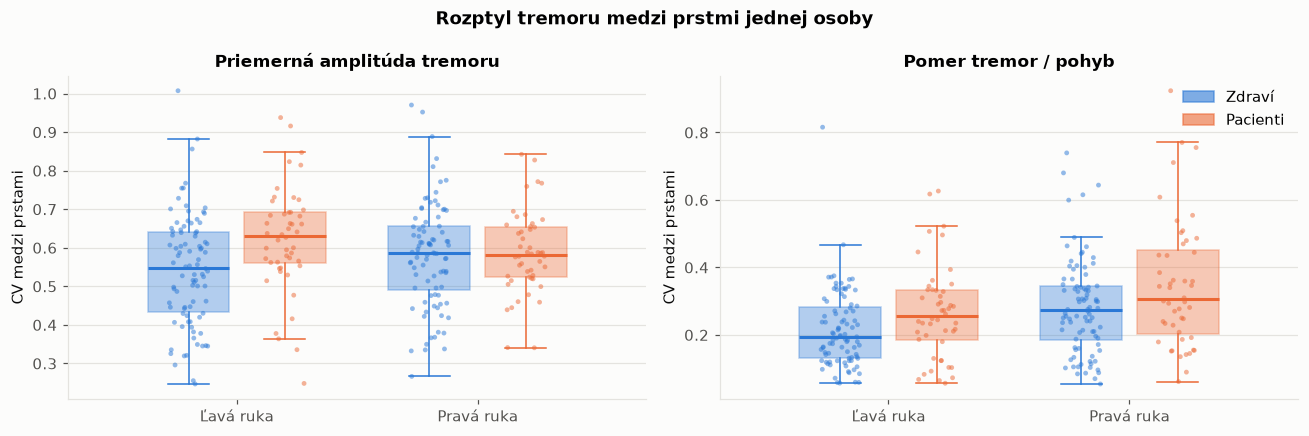

,subset,hand,feature,measure,n_a,n_b,median_a,median_b,u,p,effect_r,p_holm
0,all,Ľavá ruka,Pomer tremor / pohyb,cv,90,48,0.1949,0.2549,2622.0,0.0391,0.2139,0.0782
1,all,Ľavá ruka,Priemerná amplitúda tremoru,cv,90,48,0.5484,0.6306,2858.0,0.0018,0.3231,0.0036
2,all,Ľavá ruka,Frekvencia vrcholu tremoru [Hz],cv,90,48,0.0995,0.0644,1352.0,0.0003,-0.3741,0.0006
3,all,Ľavá ruka,Výraznosť vrcholu tremoru,cv,90,48,0.1417,0.1462,1988.0,0.4433,-0.0796,0.4433
4,all,Pravá ruka,Pomer tremor / pohyb,cv,88,48,0.2729,0.3052,2514.0,0.0675,0.1903,0.0782
5,all,Pravá ruka,Priemerná amplitúda tremoru,cv,88,48,0.5867,0.5811,2132.0,0.9292,0.0095,0.9292
6,all,Pravá ruka,Frekvencia vrcholu tremoru [Hz],cv,88,48,0.0981,0.0722,1474.0,0.0037,-0.3021,0.0037
7,all,Pravá ruka,Výraznosť vrcholu tremoru,cv,88,48,0.1418,0.1564,2490.0,0.0856,0.1790,0.1712
8,age>=50,Ľavá ruka,Pomer tremor / pohyb,cv,24,40,0.2002,0.2350,572.0,0.2045,0.1917,0.2045
9,age>=50,Ľavá ruka,Priemerná amplitúda tremoru,cv,24,40,0.5451,0.6100,654.0,0.0161,0.3625,0.0323


In [13]:
spread = tables["finger_spread_by_person"]
spread_features = ["tremor_mean_amplitude", "tremor_to_movement_ratio"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, feature in zip(axes, spread_features):
    positions, values, colors = [], [], []
    for h, hand in enumerate(HANDS):
        for g, group in enumerate(GROUPS):
            frame = spread.loc[(spread["hand"] == hand) & (spread["group"] == group), f"{feature}_cv"].dropna()
            positions.append(h * 1.0 + (g - 0.5) * 0.4)
            values.append(frame)
            colors.append(GROUP_COLORS[group])
    parts = ax.boxplot(values, positions=positions, widths=0.34, patch_artist=True, showfliers=False)
    for index, (box, median, color) in enumerate(zip(parts["boxes"], parts["medians"], colors)):
        box.set(facecolor=color, edgecolor=color, alpha=0.35)
        median.set(color=color, linewidth=2)
        # Each box owns two whiskers and two caps.
        for line in parts["whiskers"][2 * index:2 * index + 2] + parts["caps"][2 * index:2 * index + 2]:
            line.set(color=color)
    for position, frame, color in zip(positions, values, colors):
        jitter = np.random.default_rng(0).uniform(-0.08, 0.08, len(frame))
        ax.scatter(position + jitter, frame, s=10, color=color, alpha=0.5, edgecolor="none")
    ax.set_xticks([0, 1], [SK_HAND[h] for h in HANDS])
    ax.set_ylabel("CV medzi prstami")
    ax.set_title(SK_FEATURE[feature])
    ax.grid(axis="x", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS[g], alpha=0.6) for g in GROUPS]
axes[1].legend(handles, [SK_GROUP[g] for g in GROUPS])
fig.suptitle("Rozptyl tremoru medzi prstmi jednej osoby", fontweight="bold")
fig.tight_layout()
plt.show()

test = tables["finger_spread_group_test"].copy()
test["hand"] = test["hand"].map(SK_HAND)
test["feature"] = test["feature"].map(SK_FEATURE)
display(test.round(4))

## 6. Porovnanie skupín po prstoch

Mann-Whitneyho test pre každý prst a ukazovateľ. Farba = veľkosť účinku *r*
(červená: pacienti majú vyššie hodnoty, modrá: nižšie). Hviezdička = p < 0,05 po Holmovej korekcii.
Vpravo len osoby vo veku ≥ 50 rokov, kde sú skupiny vekovo porovnateľnejšie.

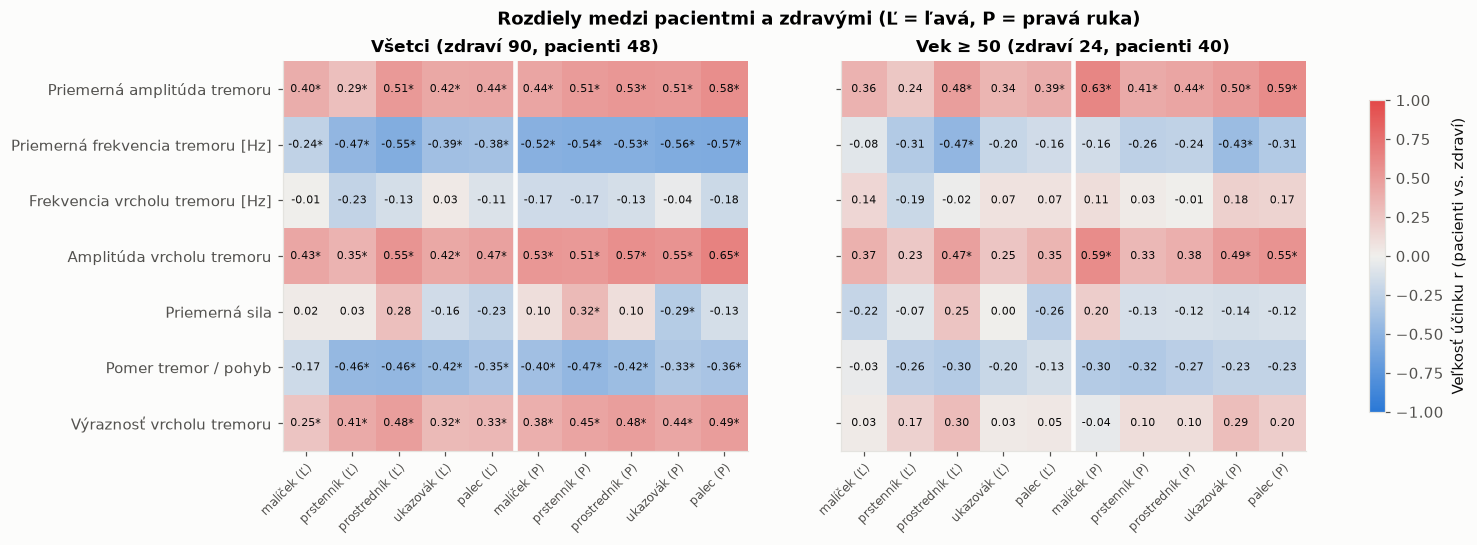

In [14]:
comparison = tables["group_comparison_by_finger"]
features = list(SK_FEATURE)
columns = [(hand, finger) for hand in HANDS for finger in FINGERS]
subsets = comparison["subset"].unique()
fig, axes = plt.subplots(1, len(subsets), figsize=(15, 4.6), sharey=True)
for ax, subset in zip(axes, subsets):
    frame = comparison.loc[comparison["subset"] == subset].set_index(["feature", "hand", "finger_name"])
    effect = np.array([[frame.loc[(f, h, n), "effect_r"] for h, n in columns] for f in features])
    p_holm = np.array([[frame.loc[(f, h, n), "p_holm"] for h, n in columns] for f in features])
    image = ax.imshow(effect, cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
    for i in range(len(features)):
        for j in range(len(columns)):
            star = "*" if p_holm[i, j] < ALPHA else ""
            ax.text(j, i, f"{effect[i, j]:.2f}{star}", ha="center", va="center", fontsize=7.5, color=TEXT)
    ax.set_xticks(range(len(columns)), [f"{SK_FINGER[n]} ({'Ľ' if h == 'left' else 'P'})" for h, n in columns],
                  fontsize=8, rotation=45, ha="right", rotation_mode="anchor")
    ax.axvline(len(FINGERS) - 0.5, color="#fcfcfb", linewidth=3)
    ax.set_yticks(range(len(features)), [SK_FEATURE[f] for f in features])
    ax.grid(False)
    n_patient, n_control = int(frame["n_b"].max()), int(frame["n_a"].max())
    title = "Všetci" if subset == "all" else f"Vek ≥ {AGE_MATCHED_MIN_AGE}"
    ax.set_title(f"{title} (zdraví {n_control}, pacienti {n_patient})")
fig.colorbar(image, ax=axes, shrink=0.8, label="Veľkosť účinku r (pacienti vs. zdraví)")
fig.suptitle("Rozdiely medzi pacientmi a zdravými (Ľ = ľavá, P = pravá ruka)", fontweight="bold", x=0.45)
plt.show()

In [15]:
left_right = tables["left_right_by_finger"].copy()
left_right = left_right.loc[left_right["p_holm"] < ALPHA]
left_right["group"] = left_right["group"].map(SK_GROUP)
left_right["finger_name"] = left_right["finger_name"].map(SK_FINGER)
left_right["feature"] = left_right["feature"].map(SK_FEATURE)
print("Významné rozdiely ľavá vs. pravá ruka (kladné r = vyššie na pravej ruke):")
display(left_right.round(4))

Významné rozdiely ľavá vs. pravá ruka (kladné r = vyššie na pravej ruke):


,group,finger,finger_name,feature,n_pairs,median_difference,p,effect_r,p_holm
0,Zdraví,1,malíček,Pomer tremor / pohyb,60,0.0261,0.0000,0.6579,0.0000
1,Zdraví,1,malíček,Priemerná amplitúda tremoru,60,0.0000,0.0001,0.5880,0.0004
5,Zdraví,2,prstenník,Priemerná amplitúda tremoru,80,-0.0000,0.0065,-0.3500,0.0262


## 7. Príklad spektra prstov

Časovo spriemerované spektrum (pokus 1, rozsah 4–15 Hz) pre pacienta s najvýraznejším
vrcholom tremoru a pre zdravú osobu s mediánovou výraznosťou. Bod = nájdený vrchol.

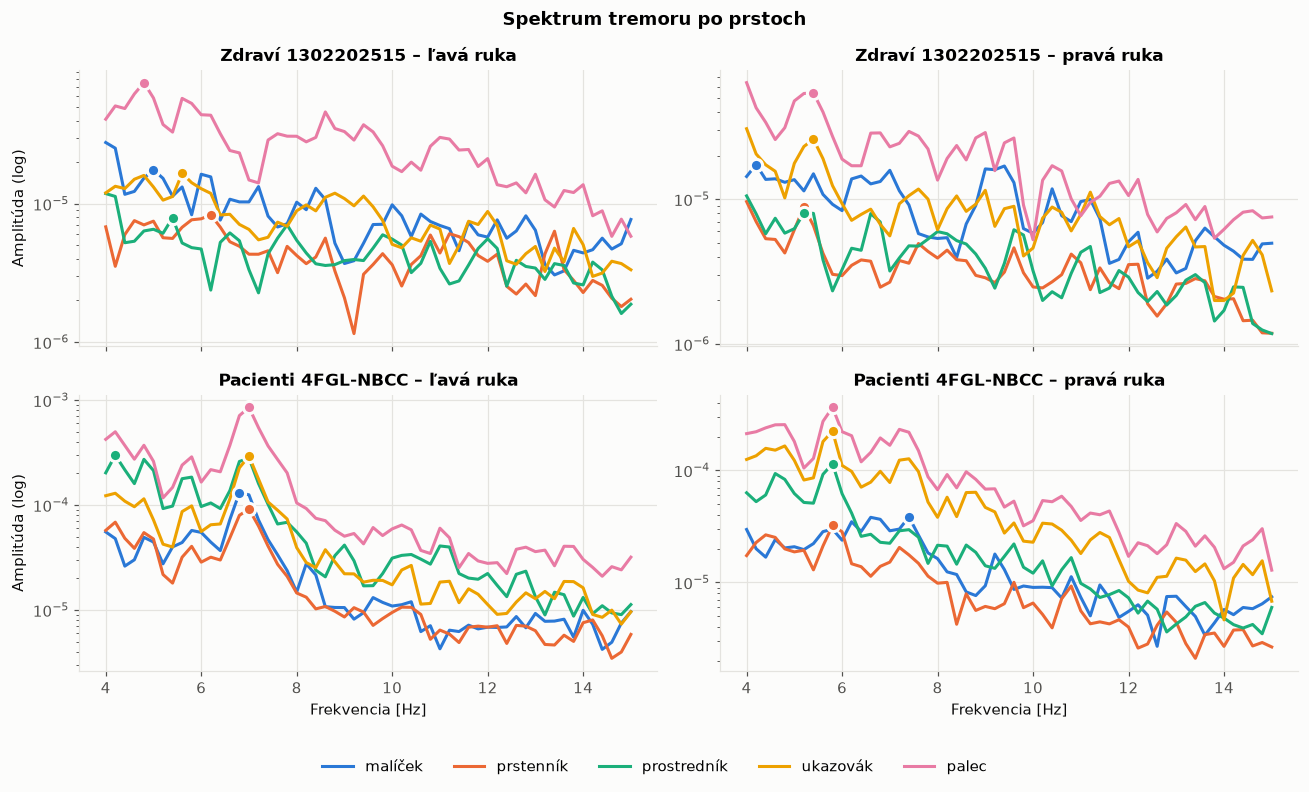

In [16]:
primary = person_fingers.loc[person_fingers["step_id"].isin(activity["step_id"].unique())]
score = primary.groupby(["patient_id", "group"])["tremor_peak_prominence"].median().reset_index()
patient_id = score.loc[score["group"] == "patient"].nlargest(1, "tremor_peak_prominence")["patient_id"].iloc[0]
controls = score.loc[score["group"] == "control"].sort_values("tremor_peak_prominence")
control_id = controls.iloc[len(controls) // 2]["patient_id"]

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for row, (person, group) in enumerate(((control_id, "control"), (patient_id, "patient"))):
    record = attempts.loc[(attempts["patient_id"] == person) & attempts["step_id"].isin(activity["step_id"])].iloc[0]
    data = load_measurement_data(resolve_project_path(record["file_path"]))
    data = data.loc[(data["attempt"] == 1) & (data["segment"] == 1)]
    peaks = attempts.loc[(attempts["file_path"] == record["file_path"]) & (attempts["attempt"] == 1)]
    for col, hand in enumerate(HANDS):
        ax = axes[row, col]
        for color, (number, finger) in zip(FINGER_COLORS, enumerate(FINGERS, start=1)):
            frequencies, _, magnitude = compute_spectrogram(data[f"{hand}_sensor_{number}"].to_numpy())
            band = band_mask(frequencies, TREMOR_BAND)
            ax.plot(frequencies[band], magnitude[band].mean(axis=1), color=color, linewidth=2, label=SK_FINGER[finger])
            peak = peaks.loc[(peaks["hand"] == hand) & (peaks["finger"] == number)].iloc[0]
            if np.isfinite(peak["tremor_peak_frequency_hz"]):
                ax.scatter(peak["tremor_peak_frequency_hz"], peak["tremor_peak_amplitude"], s=64, color=color,
                           edgecolor="#fcfcfb", linewidth=2, zorder=3)
        ax.set_yscale("log")
        ax.set_title(f"{SK_GROUP[group]} {person} – {SK_HAND[hand].lower()}")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.03))
for ax in axes[1]:
    ax.set_xlabel("Frekvencia [Hz]")
for ax in axes[:, 0]:
    ax.set_ylabel("Amplitúda (log)")
fig.suptitle("Spektrum tremoru po prstoch", fontweight="bold")
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()